# Predict weather aircraft enter holding patterns (low speed + low altitude near the airport) 
# or land normally under specific weather conditions at the airport (ICAO).

In [3]:
import pandas as pd
import sys 
import os

# find src folder
sys.path.append(os.path.abspath('..'))

from src.databases.databases import Database

db = Database()

In [4]:


# Flight data
sql_flights = """
SELECT 
fs.flight_state_id,
fs.airport_icao,
fs.aircraft_icao24,
fs.time_position,
fs.on_ground,
fs.latitude,
fs.longitude,
fs.baro_altitude,
fs.velocity,
fs.vertical_rate,
fs.true_track,
a.latitude as airport_latitude,
a.longitude as airport_longitude
FROM flight_state fs
LEFT JOIN airport a ON fs.airport_icao = a.airport_icao
"""

flight_list = db.execute_sql(sql_flights)

df_flights = pd.DataFrame(flight_list)
print(df_flights.shape)

df_flights.head()

(74665, 13)


,flight_state_id,airport_icao,aircraft_icao24,time_position,on_ground,latitude,longitude,baro_altitude,velocity,vertical_rate,true_track,airport_latitude,airport_longitude
0,1,EDDM,4bc88d,2026-10-27 12:06:20+00:00,True,48.351500,11.778200,None,6.94,None,354.38,48.353800,11.786100
1,4,EDDM,3c4a03,2026-10-27 12:07:57+00:00,False,48.360500,11.738300,518.16,67.26,-2.93,83.85,48.353800,11.786100
2,5,EDDM,3c4a22,2026-10-27 12:07:58+00:00,False,48.199200,11.478200,8107.68,273.81,10.08,119.99,48.353800,11.786100
3,6,EDDM,45211e,2026-10-27 12:07:32+00:00,True,48.355700,11.778600,None,0.00,None,174.38,48.353800,11.786100
4,7,EDDM,3d6fb7,2026-10-27 12:07:33+00:00,True,48.342100,11.768900,None,26.24,None,87.19,48.353800,11.786100


In [5]:
# Weather data
sql_weather = """
SELECT 
ws.weather_state_id,
ws.airport_icao,
ws.temperature_c,
ws.wind_speed_mps,
ws.wind_direction_deg,
ws.wind_gust_mps,
ws.cloudiness_percent,
ws.visibility_m,
ws.time_of_record,
w.main,
w.description
FROM weather_state ws
LEFT JOIN weather w ON ws.weather_id = w.weather_id
"""
weather_list = db.execute_sql(sql_weather)

df_weather = pd.DataFrame(weather_list)
print(df_weather.shape)

df_weather.head()

(6533, 11)


,weather_state_id,airport_icao,temperature_c,wind_speed_mps,wind_direction_deg,wind_gust_mps,cloudiness_percent,visibility_m,time_of_record,main,description
0,1,EDDM,16.62,4.12,90,None,0,10000.0,2026-10-27 13:09:21+00:00,Clear,clear sky
1,2,EDDF,16.94,3.09,190,None,100,10000.0,2026-10-27 13:09:21+00:00,Clouds,overcast clouds
2,3,EDDB,15.16,5.14,170,None,100,10000.0,2026-10-27 13:09:21+00:00,Clouds,overcast clouds
3,4,EDDH,14.96,5.66,170,None,100,10000.0,2026-10-27 13:09:21+00:00,Clouds,overcast clouds
4,5,EDDL,18.73,6.69,190,None,0,10000.0,2026-10-27 13:09:21+00:00,Clear,clear sky


In [6]:
# clean flight data
# only flights in the air
df_flights = df_flights[df_flights['on_ground'] == False]
# print(df_flights[df_flights['baro_altitude'].isna()])

# delete incomplete data points
df_flights = df_flights.dropna(subset=['baro_altitude', 'velocity', 'vertical_rate'])
# print(df_flights.dtypes)

# type object to type float
df_flights['latitude'] = df_flights['latitude'].astype(float)
df_flights['longitude'] = df_flights['longitude'].astype(float)
df_flights['baro_altitude'] = df_flights['baro_altitude'].astype(float)
df_flights['vertical_rate'] = df_flights['vertical_rate'].astype(float)
df_flights['velocity'] = df_flights['velocity'].astype(float)
df_flights['true_track'] = df_flights['true_track'].astype(float)
df_flights['airport_latitude'] = df_flights['airport_latitude'].astype(float)
df_flights['airport_longitude'] = df_flights['airport_longitude'].astype(float)
print(df_flights.dtypes)

# delete flights under 80 km/h (20 ms)
df_flights = df_flights[df_flights['velocity'] > 20]

# no steep climbs
df_flights = df_flights[df_flights['vertical_rate'] <= 3.0]

df_flights.isnull().sum()
# df_flights.head()


df_flights['is_holding'] = (
    ((df_flights['latitude'] - df_flights['airport_latitude']).abs() < 0.4) &
    ((df_flights['longitude'] - df_flights['airport_longitude']).abs() < 0.6) &
    (df_flights['baro_altitude'] < 3000) &
    (df_flights['velocity'] < 140) &
    (df_flights['vertical_rate'].between(-1.5, 1.5))
)
print(df_flights['is_holding'].value_counts())

flight_state_id                    int64
airport_icao                         str
aircraft_icao24                      str
time_position        datetime64[us, UTC]
on_ground                           bool
latitude                         float64
longitude                        float64
baro_altitude                    float64
velocity                         float64
vertical_rate                    float64
true_track                       float64
airport_latitude                 float64
airport_longitude                float64
dtype: object
is_holding
False    25939
True      3348
Name: count, dtype: int64


In [7]:

# clean weather data
# df_weather.isnull().sum()

# fill wind_gust_map with 0
df_weather['wind_gust_mps'] = df_weather['wind_gust_mps'].fillna(0)

# delete incomplete data points 
df_weather = df_weather.dropna(subset=['visibility_m'])

# type object to type float
df_weather['temperature_c'] = df_weather['temperature_c'].astype(float)
df_weather['wind_speed_mps'] = df_weather['wind_speed_mps'].astype(float)
df_weather['wind_gust_mps'] = df_weather['wind_gust_mps'].astype(float)

print(df_weather.dtypes)
df_weather.head()
df_weather.isnull().sum()

weather_state_id                    int64
airport_icao                          str
temperature_c                     float64
wind_speed_mps                    float64
wind_direction_deg                  int64
wind_gust_mps                     float64
cloudiness_percent                  int64
visibility_m                      float64
time_of_record        datetime64[us, UTC]
main                                  str
description                           str
dtype: object


weather_state_id      0
airport_icao          0
temperature_c         0
wind_speed_mps        0
wind_direction_deg    0
wind_gust_mps         0
cloudiness_percent    0
visibility_m          0
time_of_record        0
main                  0
description           0
dtype: int64

In [8]:
# merge flight data with weather data
df_flights = df_flights.sort_values('time_position').reset_index(drop=True)
df_weather = df_weather.sort_values('time_of_record').reset_index(drop=True)

df = pd.merge_asof(df_flights, df_weather, left_on='time_position', right_on='time_of_record', by='airport_icao')

df.isnull().sum()

# delete Rows with no weather
df = df.dropna(subset=['weather_state_id'])

In [9]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

X = df.drop(['is_holding', 'baro_altitude', 'velocity', 'vertical_rate', 'latitude', 'longitude', 'flight_state_id', 'aircraft_icao24', 'time_position','vertical_rate', 'true_track', 'airport_latitude', 'airport_longitude',
    'weather_state_id', 'time_of_record', 'description', 'on_ground'], axis=1)
y = df['is_holding']

features = ['main', 'airport_icao']
transformer = OneHotEncoder(drop='first', sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("data", transformer, features),
    ],
    remainder='passthrough'
).set_output(transform="pandas")

X_encoded = preprocessor.fit_transform(X)

print(X_encoded)
print(X_encoded.head())

       data__main_Clouds  data__main_Drizzle  data__main_Fog  data__main_Mist  \
440                  1.0                 0.0             0.0              0.0   
441                  1.0                 0.0             0.0              0.0   
442                  1.0                 0.0             0.0              0.0   
443                  1.0                 0.0             0.0              0.0   
444                  1.0                 0.0             0.0              0.0   
...                  ...                 ...             ...              ...   
29282                0.0                 0.0             0.0              0.0   
29283                0.0                 0.0             0.0              0.0   
29284                1.0                 0.0             0.0              0.0   
29285                1.0                 0.0             0.0              0.0   
29286                1.0                 0.0             0.0              0.0   

       data__main_Rain  dat

0.6755362946912242
0.6007973652279425
col_0       False  True 
is_holding              
False        3182   1928
True          375    284
              precision    recall  f1-score   support

       False       0.89      0.62      0.73      5110
        True       0.13      0.43      0.20       659

    accuracy                           0.60      5769
   macro avg       0.51      0.53      0.47      5769
weighted avg       0.81      0.60      0.67      5769



/tmp/ipykernel_482133/2584869106.py:24: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  importances.sort_values(by='Importance', ascending=False, inplace=True)


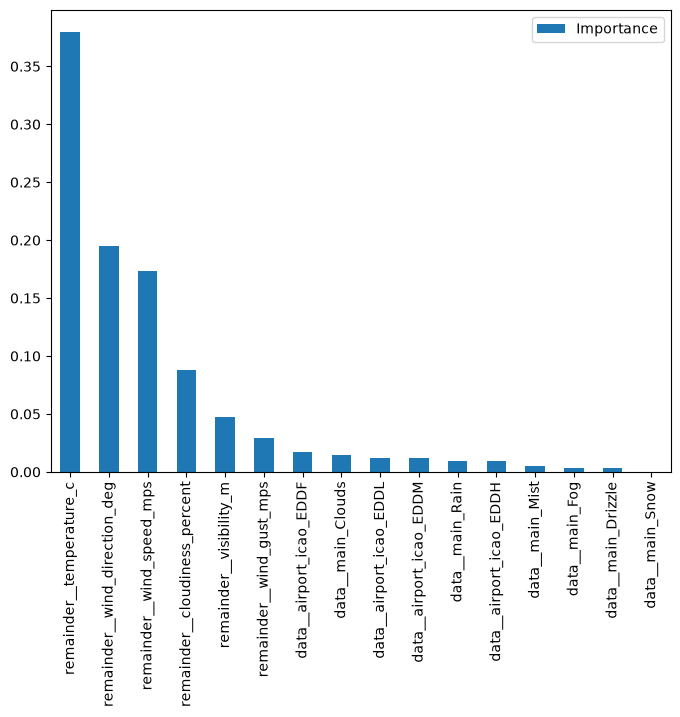

In [10]:
# train model
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.20, random_state = 42, stratify=y)

rf = RandomForestClassifier(random_state=42, class_weight='balanced')
rf.fit(X_train, y_train)

print(rf.score(X_train, y_train))
print(rf.score(X_test, y_test))

y_pred = rf.predict(X_test)

print(pd.crosstab(y_test,y_pred))
print(classification_report(y_test, y_pred))

y.value_counts(normalize=True)

importances = pd.DataFrame(rf.feature_importances_, index=X_encoded.columns, columns=['Importance'])

importances.sort_values(by='Importance', ascending=False, inplace=True)

importances.plot(kind='bar', figsize=(8,6))
plt.show()

In [11]:
import joblib

joblib.dump(
    {
        "preprocessor": preprocessor,
        "model": rf,
    },
    "../models/holding_model.joblib",
)

['../models/holding_model.joblib']